# 02 Ramachandran QC: human healthy vs cirrhotic liver (GSE136103)

Same steps as 01, for the human data. Each donor's liver was sorted into **CD45+** (immune)
and **CD45−** (non-immune) cells before sequencing, so one donor has 2–3 samples. Because of
that sorting, cell-type proportions here say little about the real liver. That is fine for
our map, but don't read abundance off it.

Cutoffs follow the paper: cells with fewer than 300 genes or more than 30% mitochondrial reads
are removed, and genes seen in fewer than 3 cells are dropped. We add the Leone Lab upper gene
cap and Scrublet.

In [1]:
import os
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from config import *
from lcm import *

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
FIG = os.path.join("figures", "02_ramachandran"); os.makedirs(FIG, exist_ok=True)
CUT = QC["ramachandran"]
samples = RAMACHANDRAN if DEV_SUBSET is None else RAMACHANDRAN[:DEV_SUBSET]
print(len(samples), "samples | cutoffs:", CUT)

20 samples | cutoffs: {'min_genes': 300, 'max_genes': 6000, 'max_pct_mt': 30}


## 1. Load (one 10x matrix per sample, Cell Ranger 2 file layout)

In [2]:
def read_10x_v2(prefix):
    """Cell Ranger 2 layout (barcodes / genes / matrix, gzipped); scanpy's reader expects v3 names."""
    a = sc.read_mtx(prefix + "matrix.mtx.gz").T          # file is genes x cells
    a.obs_names = pd.read_csv(prefix + "barcodes.tsv.gz", header=None)[0].to_numpy()
    genes = pd.read_csv(prefix + "genes.tsv.gz", sep="\t", header=None)
    a.var_names = genes[1].to_numpy()                     # column 1 = gene symbol
    a.var["gene_ids"] = genes[0].to_numpy()
    a.var_names_make_unique()
    return a

parts = []
for gsm, sample in samples:
    a = read_10x_v2(os.path.join(RAW, "GSE136103", f"{gsm}_{sample}_"))
    donor = sample.split("_")[0]
    a.obs_names = [f"rama_{sample}_{c}" for c in a.obs_names]
    a.obs["dataset"], a.obs["species"], a.obs["sample"] = "ramachandran", "human", sample
    a.obs["donor"] = f"human_{donor}"
    a.obs["condition"] = "healthy" if donor.startswith("healthy") else "disease"
    a.obs["fraction"] = "CD45+" if "cd45+" in sample else "CD45-"
    parts.append(a)
    print(f"{sample}: {a.n_obs:,} cells")

adata = ad.concat(parts, join="outer", fill_value=0)
del parts
for c in ["dataset", "species", "sample", "donor", "condition", "fraction"]:
    adata.obs[c] = adata.obs[c].astype("category")
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)
print(adata); ram("after load")

healthy1_cd45+: 1,863 cells


healthy1_cd45-A: 1,039 cells
healthy1_cd45-B: 478 cells


healthy2_cd45+: 6,571 cells


healthy2_cd45-: 4,688 cells


healthy3_cd45+: 3,295 cells


healthy3_cd45-A: 3,230 cells


... (11 outputs left out)

cirrhotic4_cd45+: 4,819 cells


cirrhotic5_cd45+: 2,922 cells


AnnData object with n_obs × n_vars = 62210 × 25534
    obs: 'dataset', 'species', 'sample', 'donor', 'condition', 'fraction'
    var: 'n_cells'
[RAM] after load process uses 0.5 GB


0.503185408

## 2. Quality control

{'mt': 13, 'ribo': 103, 'hb': 3} genes flagged


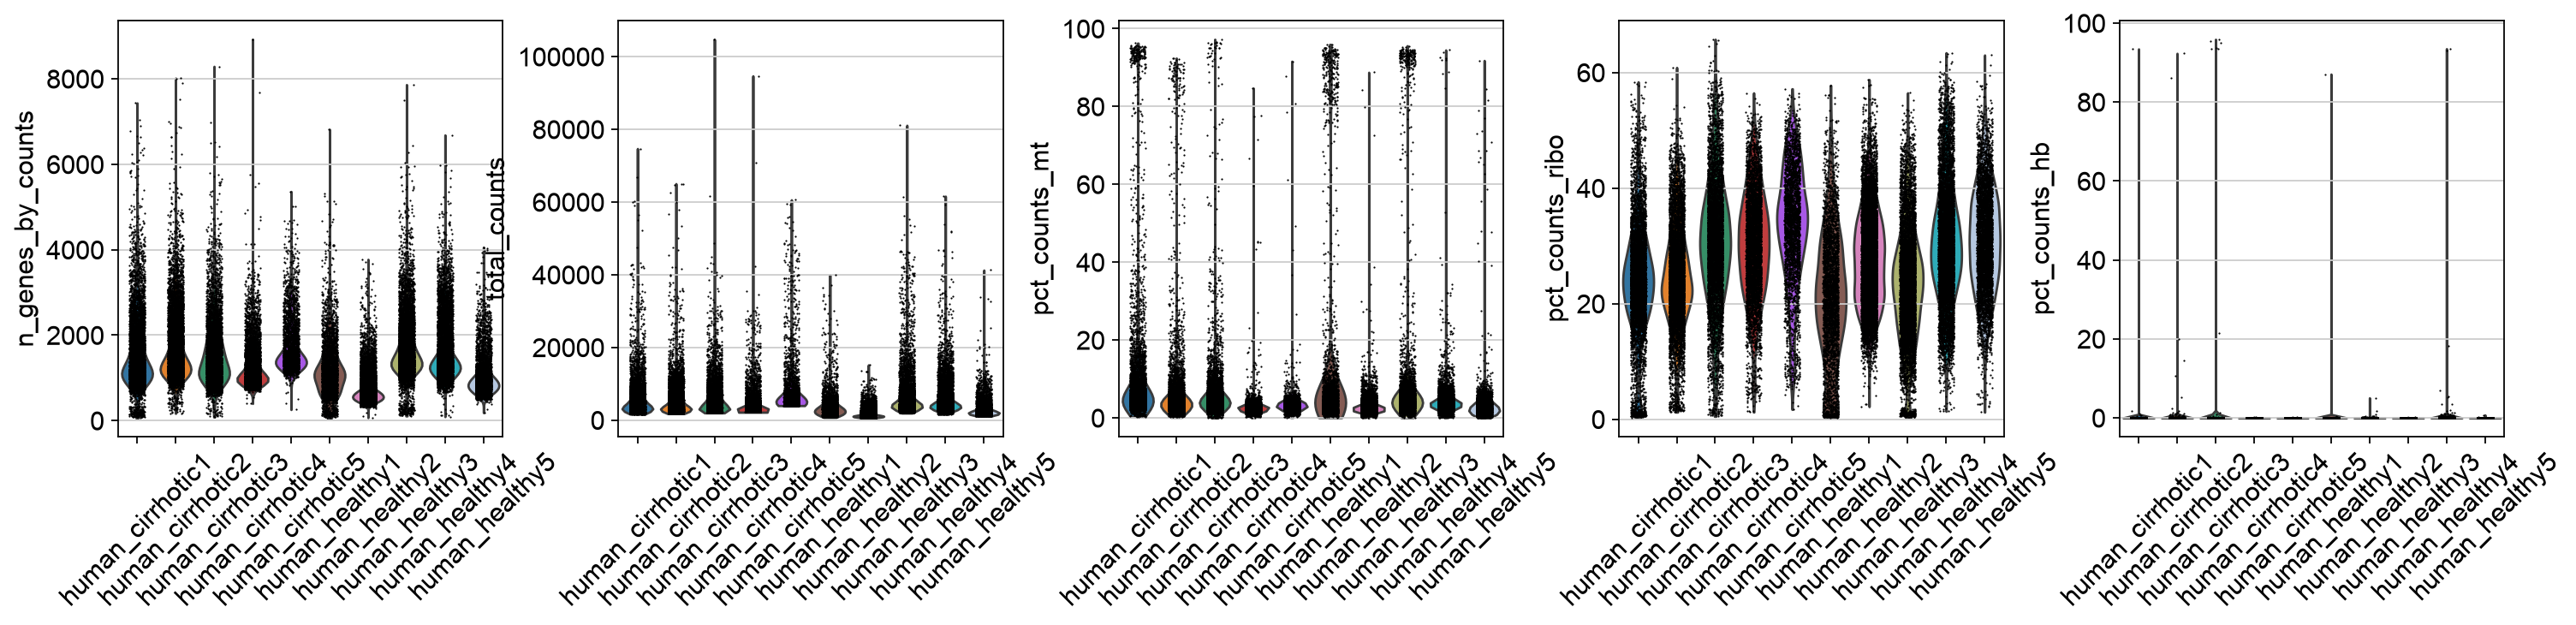

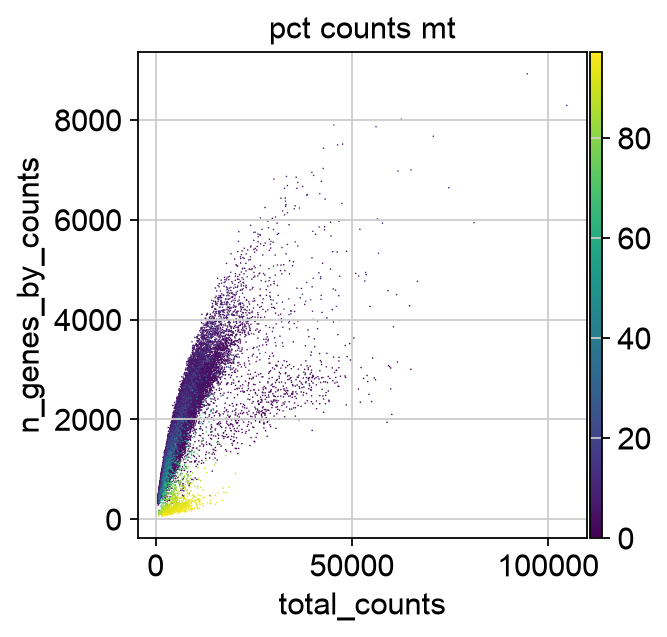

In [3]:
add_qc_metrics(adata, "human")
sc.pl.violin(adata, QC_COLS, groupby="donor", multi_panel=False, jitter=0.2, rotation=45, show=False)
plt.savefig(os.path.join(FIG, "qc_violins_before.png"), bbox_inches="tight"); plt.show()
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt", show=False)
plt.savefig(os.path.join(FIG, "qc_scatter_before.png"), bbox_inches="tight"); plt.show()

In [4]:
qc_diagnostics(adata, CUT)

           metric    p1    p5    p25    p50    p75     p95     p99
n_genes_by_counts 334.0 497.0  885.0 1231.0 1721.0  2887.5  3941.0
     total_counts 733.1 978.5 2267.2 3448.0 5395.0 12252.0 25244.3
    pct_counts_mt   0.5   1.3    2.4    3.3    4.6    11.4    86.9
  pct_counts_ribo   1.4  11.5   20.8   27.1   34.0    44.4    51.6
    pct_counts_hb   0.0   0.0    0.0    0.0    0.0     0.0     0.0

< 300 genes: 545 | >= 6000 genes: 46 | >= 30% mito: 1,270 | removed by any: 1,331 of 62,210


In [5]:
before_qc = adata.obs[["sample"]].copy()
adata = apply_qc(adata, CUT)
print(f"cells after QC cutoffs: {adata.n_obs:,}")

cells after QC cutoffs: 60,879


## 3. Doublets (Scrublet, per sample)

In [6]:
after_qc = adata.obs[["sample"]].copy()
adata = remove_doublets(adata)
print(f"cells after doublet removal: {adata.n_obs:,}"); ram("after scrublet")

sample
cirrhotic1_cd45+     0.001
cirrhotic1_cd45-A    0.001
cirrhotic1_cd45-B    0.006
cirrhotic2_cd45+     0.003
cirrhotic2_cd45-     0.008
cirrhotic3_cd45+     0.001
cirrhotic3_cd45-     0.017
cirrhotic4_cd45+     0.000
cirrhotic5_cd45+     0.001
healthy1_cd45+       0.002
healthy1_cd45-A      0.004
healthy1_cd45-B      0.000
healthy2_cd45+       0.000
healthy2_cd45-       0.018
healthy3_cd45+       0.011
healthy3_cd45-A      0.015
healthy3_cd45-B      0.003
healthy4_cd45+       0.001
healthy4_cd45-       0.012
healthy5_cd45+       0.000


cells after doublet removal: 60,541
[RAM] after scrublet process uses 0.5 GB


0.500350976

In [7]:
counts = pd.DataFrame({"loaded": before_qc["sample"].value_counts(), "after QC": after_qc["sample"].value_counts(),
                       "after doublets": adata.obs["sample"].value_counts()})
counts.loc["total"] = counts.sum()
counts.to_csv(os.path.join(FIG, "cells_per_sample.csv")); counts

,loaded,after QC,after doublets
sample,,,
cirrhotic1_cd45+,2380,2278,2275
cirrhotic1_cd45-A,1686,1571,1570
cirrhotic1_cd45-B,2046,1881,1869
cirrhotic2_cd45+,3412,3327,3316
cirrhotic2_cd45-,3673,3574,3546
cirrhotic3_cd45+,1985,1900,1898
cirrhotic3_cd45-,3602,3560,3501
cirrhotic4_cd45+,4819,4807,4807
cirrhotic5_cd45+,2922,2914,2912


## 4. Cell-type labels (CellTypist `Healthy_Human_Liver`, majority voting)

In [8]:
labels = celltypist_labels(adata, "Healthy_Human_Liver.pkl")
adata.obs = adata.obs.join(labels)
adata.obs["celltype_native"].value_counts()

/opt/anaconda3/envs/scrnaseq/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv
📂 Storing models in /Users/xinqing/.celltypist/data/models


💾 Total models to download: 1


💾 Downloading model [1/1]: Healthy_Human_Liver.pkl


/opt/anaconda3/envs/scrnaseq/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🔬 Input data has 60541 cells and 25534 genes


🔗 Matching reference genes in the model


... (5 outputs left out)

⛓️ Over-clustering input data with resolution set to 20


🗳️ Majority voting the predictions


✅ Majority voting done!


celltype_native
T cells                    20590
Endothelial cells           8064
Resident NK                 7770
Mono+mono derived cells     6659
Circulating NK/NKT          4017
Cholangiocytes              3531
Macrophages                 2930
Fibroblasts                 2326
B cells                     1914
cDC2s                       1136
Plasma cells                 901
pDCs                         331
cDC1s                        191
Hepatocytes                  128
Basophils                     53
Name: count, dtype: int64

In [9]:
pd.crosstab(adata.obs["celltype_native"], [adata.obs["condition"], adata.obs["fraction"]])

condition               disease       healthy      
fraction                  CD45+ CD45-   CD45+ CD45-
celltype_native                                    
B cells                     953   240     583   138
Basophils                    26     4      19     4
Cholangiocytes              892  1566      51  1022
Circulating NK/NKT          835   530    1682   970
Endothelial cells          1366  3608     152  2938
Fibroblasts                 368   390      32  1536
Hepatocytes                  27    57      11    33
Macrophages                 353   538     720  1319
Mono+mono derived cells    1931  1374    2441   913
Plasma cells                331   164      84   322
Resident NK                1360   714    4609  1087
T cells                    6463  1097   10484  2546
cDC1s                        27    19     106    39
cDC2s                       110   157     596   273
pDCs                        166    28     113    24

## 5. Save (raw counts in `.X`)

In [10]:
adata.X = adata.X.astype(np.float32)
safe_write(adata, os.path.join(PROCESSED, "ramachandran_qc.h5ad"))

... storing 'sample' as categorical


... storing 'donor' as categorical


... storing 'condition' as categorical


... storing 'fraction' as categorical


wrote /Volumes/Crystal Hard Drive/CSE6242_data/processed/ramachandran_qc.h5ad | 60,541 cells x 25,534 genes | 0.21 GB
